# Arroyo Capital: inversión en cine

Programación Analítica II — Ethan Schcolnik y Nicolás Gómez.

Vamos a analizar dónde invertir USD 500 millones y qué riesgos tiene la propuesta. Los datos originales quedan en `datos/`. Las explicaciones aparecen después del código, junto con las observaciones y las decisiones. Ejecutar todas las celdas en orden.


## 1.1 Cargar los dos archivos, declarar tipos y fechas


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

raiz = Path.cwd()
if not (raiz / 'datos' / 'peliculas.csv').exists():
    raiz = raiz.parent

tipos_peliculas = {
    'id_pelicula':'int64', 'titulo':'string', 'anio_estreno':'int64',
    'fecha_estreno':'string', 'genero':'string', 'clasificacion':'string',
    'pais_origen':'string', 'es_secuela':'string', 'director':'string',
    'guionista':'string', 'protagonista':'string', 'productora':'string',
    'duracion_minutos':'float64', 'puntaje_imdb':'float64',
    'cantidad_votos':'float64', 'presupuesto_usd':'float64',
    'recaudacion_mundial_usd':'float64'
}
peliculas = pd.read_csv(raiz / 'datos' / 'peliculas.csv', dtype=tipos_peliculas)
ipc = pd.read_csv(raiz / 'datos' / 'ipc_eeuu.csv',
                  dtype={'anio':'int64','ipc_eeuu':'float64'})

peliculas['fecha_convertida'] = pd.to_datetime(
    peliculas.fecha_estreno, format='mixed', dayfirst=True, errors='coerce')

print('Películas:',len(peliculas),'filas y',len(tipos_peliculas),'columnas originales')
print('IPC:',ipc.shape[0],'filas y',ipc.shape[1],'columnas')
print('Fechas que no se pudieron convertir:',peliculas.fecha_convertida.isna().sum())

display(peliculas.head(3))
display(ipc.head(3))
carpeta_salidas = raiz / 'salidas'
carpeta_salidas.mkdir(exist_ok=True)


Películas: 7740 filas y 17 columnas originales
IPC: 41 filas y 2 columnas
Fechas que no se pudieron convertir: 0


,id_pelicula,titulo,anio_estreno,fecha_estreno,genero,clasificacion,pais_origen,es_secuela,director,guionista,protagonista,productora,duracion_minutos,puntaje_imdb,cantidad_votos,presupuesto_usd,recaudacion_mundial_usd,fecha_convertida
0,15834,Hatchet II,2010,2010-07-01,Acción,Mayores de 17,Estados Unidos,Si,Adam Green,Adam Green,Danielle Harris,ArieScope Pictures,85.0,5.5,13000.0,800000.0,156190.0,2010-07-01
1,10992,Shanghai Surprise,1986,1986-08-29,Aventura,Mayores de 13,UK,No,Jim Goddard,John Kohn,Sean Penn,HandMade Films,97.0,3.2,5000.0,17000000.0,2315683.0,1986-08-29
2,15201,Mr. Magorium's Wonder Emporium,2007,2007-11-16,Comedia,Apta todo publico,Estados Unidos,No,Zach Helm,Zach Helm,Natalie Portman,Mandate Pictures,93.0,6.2,44000.0,65000000.0,69474661.0,2007-11-16


,anio,ipc_eeuu
0,1980,82.4
1,1981,90.9
2,1982,96.5


Observamos que ambos archivos se cargaron correctamente. Las fechas venían en dos formatos distintos, por lo que las convertimos a un mismo tipo de dato. Conservamos también el texto original para poder revisar diferencias.

## 1.2 Dimensiones, tipos, categorías y descripción numérica


In [2]:
print('Tipos de películas:')
display(peliculas.dtypes)
print('Tipos del IPC:')
display(ipc.dtypes)

categoricas = ['genero','clasificacion','pais_origen','es_secuela',
               'director','guionista','protagonista','productora']

display(peliculas[categoricas].nunique(dropna=False))

continuas = ['duracion_minutos','puntaje_imdb','cantidad_votos',
             'presupuesto_usd','recaudacion_mundial_usd']

display(peliculas[continuas].describe().T.round(2))

Tipos de películas:
Tipos del IPC:


id_pelicula                         int64
titulo                     string[python]
anio_estreno                        int64
fecha_estreno              string[python]
genero                     string[python]
clasificacion              string[python]
pais_origen                string[python]
es_secuela                 string[python]
director                   string[python]
guionista                  string[python]
protagonista               string[python]
productora                 string[python]
duracion_minutos                  float64
puntaje_imdb                      float64
cantidad_votos                    float64
presupuesto_usd                   float64
recaudacion_mundial_usd           float64
fecha_convertida           datetime64[ns]
dtype: object

anio          int64
ipc_eeuu    float64
dtype: object

genero             25
clasificacion      11
pais_origen        65
es_secuela          2
director         2949
guionista        4536
protagonista     2815
productora       2745
dtype: int64

,count,mean,std,min,25%,50%,75%,max
duracion_minutos,7736.0,108.83,4.486000e+01,0.0,95.0,104.0,116.0,9.990000e+02
puntaje_imdb,7737.0,6.37,1.030000e+00,0.0,5.8,6.5,7.1,9.300000e+00
cantidad_votos,7737.0,88122.35,1.633336e+05,7.0,9100.0,33000.0,93000.0,2.400000e+06
presupuesto_usd,5551.0,35000792.40,4.121558e+07,-1.0,10000000.0,20000000.0,43000000.0,3.560000e+08
recaudacion_mundial_usd,7549.0,78600686.19,1.684973e+08,-622674139.0,4515258.0,20240502.0,76019048.0,2.847246e+09


Revisamos las dimensiones, los tipos y la cantidad de categorías. Las estadísticas permiten empezar a buscar valores sospechosos, pero todavía no corregimos nada.

## 1.3 Filas duplicadas y películas repetidas


In [3]:
ID_ADICIONAL_INICIO = 90001
ID_ADICIONAL_FIN = 90014

# La fecha auxiliar no interviene al comparar las filas originales.
duplicada_exacta = peliculas[list(tipos_peliculas)].duplicated()
sin_exactas = peliculas.loc[~duplicada_exacta].copy()
ids_conflictivos = sin_exactas.duplicated(subset='id_pelicula').sum()

# Una película puede aparecer dos veces con distintos ID.
repetida_pelicula = sin_exactas.duplicated(
    subset=['titulo', 'anio_estreno'], keep=False)
peliculas_repetidas = sin_exactas.loc[repetida_pelicula].sort_values(
    ['titulo', 'id_pelicula'])
pares_repetidos = peliculas_repetidas[
    ['titulo', 'anio_estreno']].drop_duplicates()

coinciden_otros_datos = peliculas_repetidas[[columna for columna in peliculas_repetidas.columns
                         if columna not in ['id_pelicula', 'presupuesto_usd']]].duplicated(keep=False)

print('Filas exactamente duplicadas:', duplicada_exacta.sum(),
      f'({duplicada_exacta.mean():.2%} de la base original)')
print('ID repetidos con datos distintos:', ids_conflictivos)
print('Películas repetidas con distinto ID y presupuesto:', len(pares_repetidos),
      'pares /', len(peliculas_repetidas), 'filas')
print('Filas que coinciden salvo ID y presupuesto:',
      coinciden_otros_datos.sum(), 'de', len(peliculas_repetidas))

display(peliculas_repetidas[
    ['id_pelicula', 'titulo', 'anio_estreno', 'presupuesto_usd']])

# Decisión: quitamos el bloque 90001-90014 para contar cada película una vez.
version_adicional = (repetida_pelicula
                     & sin_exactas.id_pelicula.between(
                         ID_ADICIONAL_INICIO, ID_ADICIONAL_FIN))
datos = sin_exactas.loc[~version_adicional].copy()


print('Versiones adicionales retiradas:', version_adicional.sum(),
      f'({version_adicional.sum() / len(peliculas):.2%} de la base original)')
print('Filas antes:', len(peliculas),
      '| después de copias exactas:', len(sin_exactas),
      '| después de películas repetidas:', len(datos))
print('Porcentaje total retirado:',
      f'{(len(peliculas) - len(datos)) / len(peliculas):.2%}')
print('Base conservada: antes 100.00% | tras copias exactas',
      f'{len(sin_exactas) / len(peliculas):.2%}',
      '| tras películas repetidas', f'{len(datos) / len(peliculas):.2%}')
print('Películas repetidas que quedan:',
      datos.duplicated(subset=['titulo', 'anio_estreno']).sum())

Filas exactamente duplicadas: 58 (0.75% de la base original)
ID repetidos con datos distintos: 0
Películas repetidas con distinto ID y presupuesto: 14 pares / 28 filas
Filas que coinciden salvo ID y presupuesto: 28 de 28
Versiones adicionales retiradas: 14 (0.18% de la base original)
Filas antes: 7740 | después de copias exactas: 7682 | después de películas repetidas: 7668
Porcentaje total retirado: 0.93%
Base conservada: antes 100.00% | tras copias exactas 99.25% | tras películas repetidas 99.07%
Películas repetidas que quedan: 0


,id_pelicula,titulo,anio_estreno,presupuesto_usd
1970,12898,Bio-Dome,1996,15000000.0
2653,90001,Bio-Dome,1996,19697118.0
2212,13101,Breakdown,1997,36000000.0
1747,90004,Breakdown,1997,31901667.0
5906,16378,Cloudy with a Chance of Meatballs 2,2013,78000000.0
3074,90008,Cloudy with a Chance of Meatballs 2,2013,93580153.0
6101,13883,Enemy at the Gates,2001,68000000.0
5510,90011,Enemy at the Gates,2001,43107007.0
5343,12897,Executive Decision,1996,55000000.0
6287,90002,Executive Decision,1996,59619028.0


Encontramos 58 duplicados exactos y 14 versiones adicionales de películas con distinto presupuesto. Quitamos las copias exactas. Para los otros casos conservamos la versión fuera del bloque de ID 90001–90014. Es una decisión práctica para no contar dos veces la misma película; no demuestra cuál presupuesto es verdadero. La tabla muestra las filas y el porcentaje retirado.

## 1.4 Faltantes por columna y ejemplos filtrados


In [4]:
faltantes_originales = pd.DataFrame({
    'n_faltantes':datos.isna().sum(),
    'porcentaje':(100*datos.isna().mean()).round(2)
}).sort_values('n_faltantes',ascending=False)

display(faltantes_originales)

# Mostramos ejemplos de las filas filtradas por las que no tienen presupuesto.
display(datos.loc[datos.presupuesto_usd.isna(),
                  ['id_pelicula','titulo','anio_estreno','genero','presupuesto_usd']]
        .head(6))

,n_faltantes,porcentaje
presupuesto_usd,2171,28.31
recaudacion_mundial_usd,189,2.46
clasificacion,77,1.00
productora,15,0.20
duracion_minutos,4,0.05
pais_origen,3,0.04
puntaje_imdb,3,0.04
cantidad_votos,3,0.04
guionista,3,0.04
protagonista,1,0.01


,id_pelicula,titulo,anio_estreno,genero,presupuesto_usd
3,13042,Celtic Pride,1996,Comedia,NaN
5,11435,"Distant Voices, Still Lives",1988,Drama,NaN
7,10739,The Holcroft Covenant,1985,Acción,NaN
8,12429,Silent Tongue,1993,Drama,NaN
11,11791,An Angel at My Table,1990,Biografía,NaN
12,11681,Nikita,1990,Acción,NaN


El presupuesto es la columna con más faltantes. Vamos a revisar si faltan por igual en todas las décadas, géneros y países antes de decidir cómo tratarlos.

## 1.5 Valores imposibles y decisiones de limpieza


In [5]:
DURACION_NO_INFORMADA = 999
DURACIONES_INVALIDAS = [0, DURACION_NO_INFORMADA]
PUNTAJE_IMDB_MIN = 1
PUNTAJE_IMDB_MAX = 10
ANIO_INICIAL_DATOS = 1980
ANIO_FINAL_DATOS = 2020

datos_sin_corregir = datos.copy()
reglas = {
    'presupuesto_usd':datos.presupuesto_usd <= 0,
    'recaudacion_mundial_usd':datos.recaudacion_mundial_usd < 0,
    'duracion_minutos':datos.duracion_minutos.isin(DURACIONES_INVALIDAS),
    'puntaje_imdb':(~datos.puntaje_imdb.between(
        PUNTAJE_IMDB_MIN, PUNTAJE_IMDB_MAX)
                     & datos.puntaje_imdb.notna()),
    'cantidad_votos':datos.cantidad_votos <= 0
}

filas_cambios = []
for columna, mascara in reglas.items():
    # Guardamos el estado anterior para cuantificar exactamente la corrección.
    antes_pct = 100*datos[columna].isna().mean()
    afectados = int(mascara.sum())
    # Invalidamos solo la celda errónea y conservamos la película.
    datos.loc[mascara,columna] = np.nan
    filas_cambios.append({
        'columna':columna,'valores_invalidados':afectados,
        'base_afectada_pct':round(100*afectados/len(datos),2),
        'faltantes_antes_pct':round(antes_pct,2),
        'faltantes_despues_pct':round(100*datos[columna].isna().mean(),2)
    })

display(pd.DataFrame(filas_cambios))
print('Películas antes y después de invalidar valores:',
      len(datos_sin_corregir), 'y', len(datos))

# Desglosamos cada regla con los valores anteriores a la corrección.
print('Presupuestos en cero:', (datos_sin_corregir.presupuesto_usd == 0).sum(),
      '| negativos:', (datos_sin_corregir.presupuesto_usd < 0).sum())
print('Recaudaciones negativas:',
      (datos_sin_corregir.recaudacion_mundial_usd < 0).sum())
print('Duraciones de 0 minutos:',
      (datos_sin_corregir.duracion_minutos == 0).sum(),
      '| de 999 minutos:',
      (datos_sin_corregir.duracion_minutos == DURACION_NO_INFORMADA).sum())
print('Puntajes IMDb menores que 1:',
      (datos_sin_corregir.puntaje_imdb < PUNTAJE_IMDB_MIN).sum(),
      '| mayores que 10:',
      (datos_sin_corregir.puntaje_imdb > PUNTAJE_IMDB_MAX).sum())
print('Cantidad de votos en cero o negativa:',
      (datos_sin_corregir.cantidad_votos <= 0).sum())
print('Años fuera de 1980–2020:',
      (~datos_sin_corregir.anio_estreno.between(
          ANIO_INICIAL_DATOS, ANIO_FINAL_DATOS)).sum())

print('\nEjemplos originales de valores imposibles:')
mascara_ejemplos = (reglas['recaudacion_mundial_usd']
                    | reglas['duracion_minutos'] | reglas['puntaje_imdb'])
display(datos_sin_corregir.loc[mascara_ejemplos,
    ['titulo','duracion_minutos','puntaje_imdb','recaudacion_mundial_usd']]
    .head(8))

Películas antes y después de invalidar valores: 7668 y 7668
Presupuestos en cero: 26 | negativos: 22
Recaudaciones negativas: 11
Duraciones de 0 minutos: 18 | de 999 minutos: 16
Puntajes IMDb menores que 1: 22 | mayores que 10: 0
Cantidad de votos en cero o negativa: 0
Años fuera de 1980–2020: 0

Ejemplos originales de valores imposibles:


,columna,valores_invalidados,base_afectada_pct,faltantes_antes_pct,faltantes_despues_pct
0,presupuesto_usd,48,0.63,28.31,28.94
1,recaudacion_mundial_usd,11,0.14,2.46,2.61
2,duracion_minutos,34,0.44,0.05,0.50
3,puntaje_imdb,22,0.29,0.04,0.33
4,cantidad_votos,0,0.00,0.04,0.04


,titulo,duracion_minutos,puntaje_imdb,recaudacion_mundial_usd
50,Ant-Man and the Wasp,118.0,7.0,-622674139.0
60,Bliss,999.0,6.9,NaN
305,The Past,130.0,0.0,12673462.0
377,Rollerball,98.0,0.0,25852764.0
560,The Butterfly Effect,113.0,0.0,96822421.0
575,Madea's Family Reunion,0.0,5.3,63368939.0
656,Princess Caraboo,97.0,0.0,3062530.0
696,The Family,999.0,6.3,78418811.0


Encontramos presupuestos no positivos, recaudaciones negativas, duraciones de 0 o 999 minutos y puntajes fuera de la escala. Reemplazamos solo esas celdas por NaN porque desconocemos sus valores verdaderos. Conservamos las películas. La tabla compara los faltantes antes y después y el porcentaje afectado.

## 1.6 Presupuestos con escala dudosa


In [6]:
PRESUPUESTO_BAJO_MAX = 1_000_000
RECAUDACION_ALTA_MIN = 20_000_000
MULTIPLO_EXTREMO_MIN = 100
MULTIPLO_MODERADO_MAX = 20

# Cociente diagnóstico de dos columnas originales; todavía no es el ROI de la etapa 2.
datos['recaudacion_sobre_presupuesto'] = (
    datos.recaudacion_mundial_usd / datos.presupuesto_usd)

datos['escala_dudosa'] = (
    (datos.presupuesto_usd > 0)
    & (datos.presupuesto_usd < PRESUPUESTO_BAJO_MAX)
    & (datos.recaudacion_mundial_usd >= RECAUDACION_ALTA_MIN)
    & (datos.recaudacion_sobre_presupuesto > MULTIPLO_EXTREMO_MIN)
)

print('Candidatas a escala dudosa:',datos.escala_dudosa.sum(),
      f'({datos.escala_dudosa.mean():.2%} de la base depurada)')

# Primera tabla: presupuestos pequeños con recaudación muy alta.
print('Presupuestos pequeños con recaudación muy alta:')
display(datos.loc[datos.escala_dudosa,
                  ['titulo','anio_estreno','presupuesto_usd',
                   'recaudacion_mundial_usd','recaudacion_sobre_presupuesto']]
        .sort_values('recaudacion_sobre_presupuesto',ascending=False)
        .head(8).round(1))

# Segunda tabla: presupuestos pequeños con una relación más moderada.
print('Presupuestos pequeños con una relación más moderada:')
display(datos.loc[(datos.presupuesto_usd > 0)
                  & (datos.presupuesto_usd < PRESUPUESTO_BAJO_MAX)
                  & datos.recaudacion_sobre_presupuesto.between(
                      0, MULTIPLO_MODERADO_MAX),
                  ['titulo','presupuesto_usd','recaudacion_mundial_usd',
                   'recaudacion_sobre_presupuesto']].head(6).round(1))

Candidatas a escala dudosa: 31 (0.40% de la base depurada)
Presupuestos pequeños con recaudación muy alta:
Presupuestos pequeños con una relación más moderada:


,titulo,anio_estreno,presupuesto_usd,recaudacion_mundial_usd,recaudacion_sobre_presupuesto
264,Platoon,1986,6000.0,138545632.0,23090.9
4439,Bean,1997,18000.0,251212670.0,13956.3
5927,Paranormal Activity,2007,15000.0,193355800.0,12890.4
1882,"Good Night, and Good Luck.",2005,7000.0,54641191.0,7805.9
3336,Sex and the City,2008,65000.0,418765519.0,6442.5
448,Guardians of the Galaxy Vol. 2,2017,200000.0,863756051.0,4318.8
1648,The Blair Witch Project,1999,60000.0,248639099.0,4144.0
283,21 & Over,2013,13000.0,48065672.0,3697.4


,titulo,presupuesto_usd,recaudacion_mundial_usd,recaudacion_sobre_presupuesto
0,Hatchet II,800000.0,156190.0,0.2
6,Re-Animator,900000.0,2023414.0,2.2
70,Welcome to the Dollhouse,800000.0,4569019.0,5.7
100,The Canyons,250000.0,270185.0,1.1
217,Living in Oblivion,500000.0,1111790.0,2.2
252,The Brother from Another Planet,350000.0,3677209.0,10.5


Un presupuesto bajo no demuestra un error. Al cruzarlo con la recaudación encontramos casos para investigar. Dejamos una marca de escala dudosa y no multiplicamos todos los presupuestos automáticamente: también existen éxitos reales muy baratos.

## 1.7 Normalizar categorías


In [7]:
categorias_clave = ['genero','clasificacion','pais_origen','es_secuela',
                    'productora']
# Guardamos los valores previos para medir los cambios.
antes_categorias = datos[categorias_clave].copy()

# Decisión: unificamos variantes para no dividir una categoría al agrupar.
mapa_genero = {'accion':'Acción','biografia':'Biografía',
               'animacion':'Animación','ciencia ficcion':'Ciencia ficción'}
datos['genero'] = (datos.genero.str.strip().str.lower()
                   .replace(mapa_genero).str.capitalize())

mapa_clasificacion = {
    'atp':'ATP','apta todo publico':'ATP',
    'supervision parental':'Supervisión parental',
    'supervisión parental':'Supervisión parental',
    'mayores de 13':'Mayores de 13','mayores de 17':'Mayores de 17',
    'solo adultos':'Solo adultos','sin clasificar':'Sin clasificar'
}
datos['clasificacion'] = (datos.clasificacion.str.strip().str.lower()
                           .replace(mapa_clasificacion).fillna('No informado'))

datos['pais_origen'] = datos.pais_origen.str.strip().replace({
    'EE.UU.':'Estados Unidos','UK':'Reino Unido',
    'Canada':'Canadá','Japon':'Japón','Espania':'España','Mexico':'México'
})

datos['es_secuela'] = datos.es_secuela.str.strip()
datos['productora'] = datos.productora.str.strip().str.title()

# Contamos las filas y categorías afectadas en cada columna.
filas_categorias=[]
for columna in categorias_clave:
    modificadas=(antes_categorias[columna].fillna('') !=
                 datos[columna].fillna('')).sum()
    filas_categorias.append({
        'columna':columna,
        'categorias_antes':antes_categorias[columna].nunique(dropna=False),
        'filas_modificadas':int(modificadas),
        'base_afectada_pct':round(100*modificadas/len(datos),2),
        'no_nulos_antes_pct':round(100*antes_categorias[columna].notna().mean(),2),
        'no_nulos_despues_pct':round(100*datos[columna].notna().mean(),2),
        'categorias_despues':datos[columna].nunique(dropna=False)
    })

print('Cambios en las variables categóricas:')
display(pd.DataFrame(filas_categorias))

Cambios en las variables categóricas:


,columna,categorias_antes,filas_modificadas,base_afectada_pct,no_nulos_antes_pct,no_nulos_despues_pct,categorias_despues
0,genero,25,696,9.08,100.00,100.00,18
1,clasificacion,11,961,12.53,99.00,100.00,7
2,pais_origen,65,764,9.96,99.96,99.96,59
3,es_secuela,2,0,0.00,100.00,100.00,2
4,productora,2745,2060,26.86,99.80,99.80,2384


Unificamos espacios, mayúsculas y nombres equivalentes para no dividir una misma categoría al agrupar. Los porcentajes afectados están en la tabla. La categoría No informado sigue representando información desconocida; no recuperamos ese dato.

## 1.8 Cobertura temporal


In [8]:
ANIO_COBERTURA_REGULAR_INICIO = 1985
ANIO_COBERTURA_REGULAR_FIN = 2019

cobertura = datos.groupby('anio_estreno').agg(
    peliculas=('id_pelicula','size'),
    con_presupuesto=('presupuesto_usd','count'),
    con_recaudacion=('recaudacion_mundial_usd','count')).reset_index()
cobertura['sin_recaudacion_pct'] = (
    100*(1-cobertura.con_recaudacion/cobertura.peliculas)).round(1)

display(pd.concat([cobertura.head(6),cobertura.iloc[-6:]]))

print('Años presentes:',cobertura.anio_estreno.nunique(),
      '| rango:',cobertura.anio_estreno.min(),'-',cobertura.anio_estreno.max())
print(f'Películas por año entre {ANIO_COBERTURA_REGULAR_INICIO} y '
      f'{ANIO_COBERTURA_REGULAR_FIN}: mínimo',
      cobertura.loc[cobertura.anio_estreno.between(
          ANIO_COBERTURA_REGULAR_INICIO, ANIO_COBERTURA_REGULAR_FIN),
          'peliculas'].min(),
      'y máximo',
      cobertura.loc[cobertura.anio_estreno.between(
          ANIO_COBERTURA_REGULAR_INICIO, ANIO_COBERTURA_REGULAR_FIN),
          'peliculas'].max())

# Comprobamos si el año declarado coincide con la fecha de estreno.
anio_distinto = ((datos.fecha_convertida.dt.year != datos.anio_estreno)
                 & datos.fecha_convertida.notna())
print('Año declarado distinto del año de fecha:',anio_distinto.sum(),
      f'({anio_distinto.mean():.1%})')
print('Años de películas sin IPC:',
      len(set(datos.anio_estreno)-set(ipc.anio)))

Años presentes: 41 | rango: 1980 - 2020
Películas por año entre 1985 y 2019: mínimo 200 y máximo 200
Año declarado distinto del año de fecha: 1297 (16.9%)
Años de películas sin IPC: 0


,anio_estreno,peliculas,con_presupuesto,con_recaudacion,sin_recaudacion_pct
0,1980,92,47,80,13.0
1,1981,113,68,104,8.0
2,1982,126,74,119,5.6
3,1983,144,89,128,11.1
4,1984,168,89,158,6.0
5,1985,200,98,177,11.5
35,2015,200,155,199,0.5
36,2016,200,159,199,0.5
37,2017,200,132,199,0.5
38,2018,200,141,199,0.5


La cobertura no es pareja: 2020 tiene solo 25 películas y los primeros años también tienen menos títulos. Además, algunas fechas no coinciden con el año declarado. Conservamos anio_estreno porque es el año al que la consigna asigna los importes.

## 1.9 ¿Falta presupuesto al azar?


In [9]:
ANIOS_POR_DECADA = 10

# Marcamos los faltantes para comparar grupos sin borrar ni imputar filas.
datos['sin_presupuesto'] = datos.presupuesto_usd.isna()
datos['decada'] = (datos.anio_estreno // ANIOS_POR_DECADA) * ANIOS_POR_DECADA

def tabla_faltantes(columna):
    tabla = datos.groupby(columna,dropna=False).agg(
        peliculas=('id_pelicula','size'),
        sin_presupuesto_pct=('sin_presupuesto','mean')).reset_index()
    tabla['sin_presupuesto_pct'] = (100*tabla.sin_presupuesto_pct).round(1)
    return tabla.sort_values('peliculas',ascending=False)

print('Por década:')
display(tabla_faltantes('decada'))

print('Por género:')
display(tabla_faltantes('genero'))

print('Por país:')
display(tabla_faltantes('pais_origen'))

sin_presupuesto = int(datos.sin_presupuesto.sum())
con_ambos = int((datos.presupuesto_usd.notna()
                 & datos.recaudacion_mundial_usd.notna()).sum())
print('Sin presupuesto:',sin_presupuesto,
      f'({sin_presupuesto/len(datos):.1%} de {len(datos)} películas)')
print('Con presupuesto y recaudación para análisis futuro:',con_ambos,
      f'({con_ambos/len(datos):.1%} de la base depurada)')

Por década:
Por género:
Por país:
Sin presupuesto: 2219 (28.9% de 7668 películas)
Con presupuesto y recaudación para análisis futuro: 5383 (70.2% de la base depurada)


,decada,peliculas,sin_presupuesto_pct
1,1990,2000,31.6
3,2010,2000,24.8
2,2000,2000,18.0
0,1980,1643,43.9
4,2020,25,40.0


,genero,peliculas,sin_presupuesto_pct
5,Comedia,2245,33.5
0,Acción,1705,17.0
7,Drama,1518,42.5
13,Policial,551,26.9
3,Biografía,443,28.9
2,Aventura,427,23.9
1,Animación,338,18.9
16,Terror,322,18.0
9,Fantasía,44,4.5
11,Misterio,20,15.0


,pais_origen,peliculas,sin_presupuesto_pct
16,Estados Unidos,5475,20.7
44,Reino Unido,816,40.0
19,Francia,279,62.4
8,Canadá,190,40.5
0,Alemania,117,32.5
4,Australia,92,54.3
31,Japón,81,60.5
23,India,62,85.5
29,Italia,61,68.9
15,España,47,63.8


Los presupuestos faltantes no se distribuyen de forma uniforme. Por ejemplo, hay más faltantes en los años 1980 que en los 2000 y en drama que en acción.

Decisión: conservar las películas en la base general y no inventar presupuestos. Para calcular retornos usamos solo las que tienen presupuesto y recaudación. Esto puede dejar algunos grupos menos representados.

# Etapa 2: creación de variables

## 2.1 Presupuesto y recaudación en dólares de 2020


In [10]:
ANIO_BASE_IPC = 2020
USD_POR_MILLON = 1_000_000

# Cada año del IPC debe aportar un solo valor al cruce.
ipc_para_cruce = ipc.rename(columns={'anio':'anio_estreno'})
print('Años repetidos en IPC:', ipc_para_cruce.anio_estreno.duplicated().sum())

filas_antes_ipc = len(datos)
datos = datos.merge(ipc_para_cruce, on='anio_estreno', how='left')
print('Películas antes y después del cruce:', filas_antes_ipc, 'y', len(datos))
print('Películas sin IPC:', datos.ipc_eeuu.isna().sum())

ipc_base = ipc.loc[ipc.anio == ANIO_BASE_IPC, 'ipc_eeuu'].iloc[0]
datos['factor_a_2020'] = ipc_base / datos.ipc_eeuu
datos['presupuesto_2020_usd'] = (
    datos.presupuesto_usd * datos.factor_a_2020)
datos['recaudacion_2020_usd'] = (
    datos.recaudacion_mundial_usd * datos.factor_a_2020)

print(f'IPC de referencia, año {ANIO_BASE_IPC}:', ipc_base)
print('Presupuestos disponibles antes y después:',
      datos.presupuesto_usd.notna().sum(), 'y',
      datos.presupuesto_2020_usd.notna().sum())
print('Recaudaciones disponibles antes y después:',
      datos.recaudacion_mundial_usd.notna().sum(), 'y',
      datos.recaudacion_2020_usd.notna().sum())

# Mostramos importes en millones para que la comparación sea legible.
muestra_1980 = datos.loc[(datos.anio_estreno == ANIO_INICIAL_DATOS)
                        & datos.presupuesto_usd.notna()
                        & datos.recaudacion_mundial_usd.notna()].head(3).copy()
muestra_1980['presupuesto_corriente_millones'] = (
    muestra_1980.presupuesto_usd / USD_POR_MILLON)
muestra_1980['presupuesto_2020_millones'] = (
    muestra_1980.presupuesto_2020_usd / USD_POR_MILLON)
muestra_1980['recaudacion_corriente_millones'] = (
    muestra_1980.recaudacion_mundial_usd / USD_POR_MILLON)
muestra_1980['recaudacion_2020_millones'] = (
    muestra_1980.recaudacion_2020_usd / USD_POR_MILLON)

print('Ejemplos de', ANIO_INICIAL_DATOS, ': importes en millones de USD:')
display(muestra_1980[['titulo','factor_a_2020',
                     'presupuesto_corriente_millones',
                     'presupuesto_2020_millones',
                     'recaudacion_corriente_millones',
                     'recaudacion_2020_millones']].round(2))

Años repetidos en IPC: 0
Películas antes y después del cruce: 7668 y 7668
Películas sin IPC: 0
IPC de referencia, año 2020: 258.8
Presupuestos disponibles antes y después: 5449 y 5449
Recaudaciones disponibles antes y después: 7468 y 7468
Ejemplos de 1980 : importes en millones de USD:


,titulo,factor_a_2020,presupuesto_corriente_millones,presupuesto_2020_millones,recaudacion_corriente_millones,recaudacion_2020_millones
167,Heaven's Gate,3.14,44.0,138.19,3.48,10.94
314,The Final Countdown,3.14,12.0,37.69,16.65,52.29
328,Stardust Memories,3.14,10.0,31.41,10.39,32.63


Multiplicamos cada importe por IPC de 2020 / IPC del año de estreno. Así todos quedan expresados en dólares con el poder de compra de 2020. No cambia el dinero que recibió cada película; cambia la unidad de comparación. El cruce conserva todas las filas y no completa presupuestos faltantes.

## 2.2 Retorno estimado y recuperación de la inversión


In [11]:
# Supuestos fijos del caso; se nombran como constantes, como en Clean Code.
PORCION_BOLETERIA_ESTUDIO = 0.50
MARKETING_SOBRE_PRESUPUESTO = 0.50
UMBRAL_RECUPERO = 2.5

# El mismo factor de IPC en numerador y denominador deja igual el múltiplo.
datos['multiplo_boleteria'] = (
    datos.recaudacion_2020_usd / datos.presupuesto_2020_usd)
ingreso_estudio_estimado = (
    datos.recaudacion_2020_usd * PORCION_BOLETERIA_ESTUDIO)
costo_total_estimado = (
    datos.presupuesto_2020_usd * (1 + MARKETING_SOBRE_PRESUPUESTO))
datos['roi_salas_estimado'] = (
    (ingreso_estudio_estimado - costo_total_estimado) / costo_total_estimado)

# Sin las dos cifras, no asignamos un resultado de recuperación.
con_ambos = (datos.presupuesto_2020_usd.notna()
             & datos.recaudacion_2020_usd.notna())
datos['recupero_2_5x'] = 'Sin datos'
datos.loc[con_ambos, 'recupero_2_5x'] = 'No'
datos.loc[con_ambos & (datos.multiplo_boleteria >= UMBRAL_RECUPERO),
          'recupero_2_5x'] = 'Sí'

print('ROI calculable:', datos.roi_salas_estimado.notna().sum(),
      f'({datos.roi_salas_estimado.notna().mean():.1%} de la base)')
print('Con escala de presupuesto dudosa entre los ROI calculables:',
      (con_ambos & datos.escala_dudosa).sum())
print('Películas por resultado de la regla 2,5×:')
display(datos.recupero_2_5x.value_counts().rename('peliculas'))

columnas_ejemplo = ['titulo','anio_estreno','multiplo_boleteria',
                    'roi_salas_estimado','recupero_2_5x']
ejemplos_roi = pd.concat([
    datos.loc[datos.recupero_2_5x == 'Sí', columnas_ejemplo].head(2),
    datos.loc[datos.recupero_2_5x == 'No', columnas_ejemplo].head(2),
    datos.loc[datos.recupero_2_5x == 'Sin datos', columnas_ejemplo].head(2)
])
print('Ejemplos de las variables nuevas:')
display(ejemplos_roi.round(2))

ROI calculable: 5383 (70.2% de la base)
Con escala de presupuesto dudosa entre los ROI calculables: 31
Películas por resultado de la regla 2,5×:
Ejemplos de las variables nuevas:


recupero_2_5x
No           3269
Sin datos    2285
Sí           2114
Name: peliculas, dtype: int64

,titulo,anio_estreno,multiplo_boleteria,roi_salas_estimado,recupero_2_5x
9,Another 48 Hrs.,1990,4.04,0.35,Sí
10,The American,2010,3.39,0.13,Sí
0,Hatchet II,2010,0.20,-0.93,No
1,Shanghai Surprise,1986,0.14,-0.95,No
3,Celtic Pride,1996,NaN,NaN,Sin datos
5,"Distant Voices, Still Lives",1988,NaN,NaN,Sin datos


La recaudación mundial no es ganancia. Suponemos que el estudio recibe el 50 % y que marketing y distribución cuestan otro 50 % del presupuesto. El ROI es (ingreso del estudio − costo total) / costo total.

Por separado aplicamos la regla comercial de 2,5× que pide la consigna. Con los costos del modelo, el ROI llega a cero en 3×. Por eso una película puede cumplir la regla de 2,5× y todavía tener ROI negativo. Si falta presupuesto o recaudación, dejamos el resultado como Sin datos.

# Etapa 3: análisis de negocio

## 3.1 ¿Creció la industria?


Recaudación mediana por década completa, en USD millones:
Cobertura del último año, excluido del gráfico:


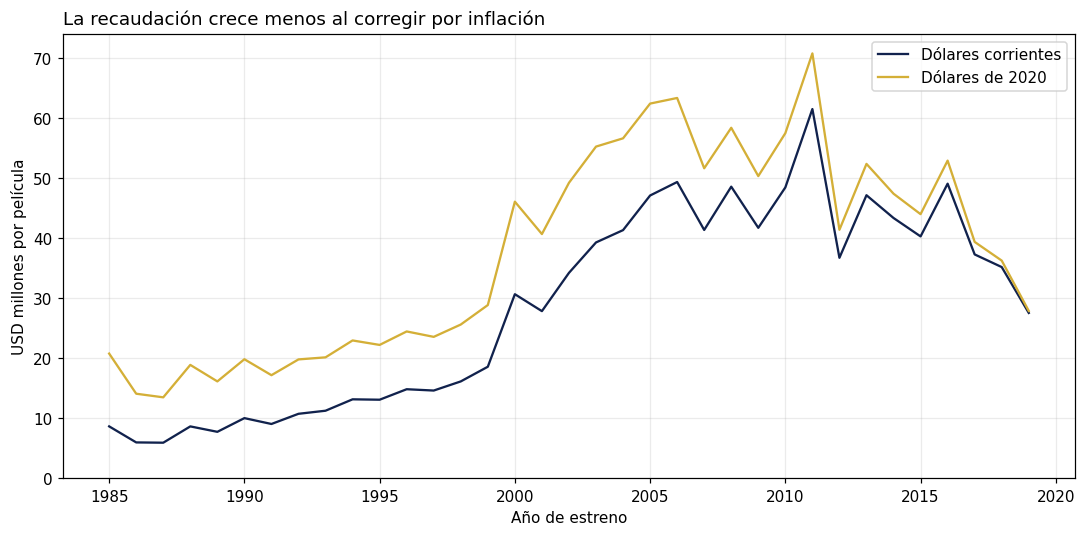

,decada,peliculas,nominal_mediana_millones,real_mediana_millones
0,1990,2000,12.89,22.15
1,2000,2000,40.42,53.42
2,2010,2000,41.68,45.81


,anio_estreno,peliculas,con_recaudacion,sin_recaudacion_pct
40,2020,25,15,40.0


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Paleta usada en las clases: azul para la serie base y dorado para destacar.
AZUL_GRAFICO = '#11224D'
AZUL_CLARO_GRAFICO = '#6699CC'
DORADO_GRAFICO = '#D4AF37'
DECADA_COMPARACION_INICIO = 1990

evolucion = datos.groupby('anio_estreno').agg(
    peliculas=('id_pelicula','size'),
    con_recaudacion=('recaudacion_mundial_usd','count'),
    nominal_mediana=('recaudacion_mundial_usd','median'),
    real_mediana=('recaudacion_2020_usd','median')).reset_index()
evolucion['sin_recaudacion_pct'] = (
    100 * (1 - evolucion.con_recaudacion / evolucion.peliculas)).round(1)
evolucion['nominal_millones'] = evolucion.nominal_mediana / USD_POR_MILLON
evolucion['real_millones'] = evolucion.real_mediana / USD_POR_MILLON

serie_regular = evolucion.loc[evolucion.anio_estreno.between(
    ANIO_COBERTURA_REGULAR_INICIO, ANIO_COBERTURA_REGULAR_FIN)]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(serie_regular.anio_estreno, serie_regular.nominal_millones,
        label='Dólares corrientes', color=AZUL_GRAFICO)
ax.plot(serie_regular.anio_estreno, serie_regular.real_millones,
        label='Dólares de 2020', color=DORADO_GRAFICO)
ax.set_title('La recaudación crece menos al corregir por inflación', loc='left')
ax.set_xlabel('Año de estreno')
ax.set_ylabel('USD millones por película')
ax.set_ylim(0, None)
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(carpeta_salidas / '34_grafico.png', dpi=150, bbox_inches='tight')
plt.show()

# Comparamos décadas completas para resumir la tendencia de las dos series.
decadas_completas = datos.loc[datos.anio_estreno.between(
    DECADA_COMPARACION_INICIO, ANIO_COBERTURA_REGULAR_FIN)]
resumen_decadas = decadas_completas.groupby('decada').agg(
    peliculas=('id_pelicula','size'),
    nominal_mediana=('recaudacion_mundial_usd','median'),
    real_mediana=('recaudacion_2020_usd','median')).reset_index()
resumen_decadas['nominal_mediana_millones'] = (
    resumen_decadas.nominal_mediana / USD_POR_MILLON)
resumen_decadas['real_mediana_millones'] = (
    resumen_decadas.real_mediana / USD_POR_MILLON)

print('Recaudación mediana por década completa, en USD millones:')
display(resumen_decadas[
    ['decada','peliculas','nominal_mediana_millones',
     'real_mediana_millones']].round(2))
print('Cobertura del último año, excluido del gráfico:')
display(evolucion.loc[evolucion.anio_estreno == ANIO_BASE_IPC,
                      ['anio_estreno','peliculas','con_recaudacion',
                       'sin_recaudacion_pct']])

**Observaciones 3.1:** en esta base, la película mediana de los años 2010 recaudó más que la de los años 1990. En dólares corrientes, la recaudación mediana pasó de USD 12,89 a 41,68 millones: parece haberse multiplicado por 3,2. Al expresar ambas décadas en dólares de 2020, pasó de USD 22,15 a 45,81 millones: creció cerca de 2,1 veces. **Parte del aumento se explica por la inflación, pero también hubo crecimiento después de corregirla.** No usamos 2020 para cerrar la comparación porque solo tiene 25 películas y al 40 % le falta la recaudación.

## 3.2 ¿Cuánto rinde cada tipo de película?


In [13]:
PRESUPUESTO_MIN_ANALISIS = 1_000_000
MIN_PELICULAS_COMPARABLES = 30

con_roi = datos.loc[datos.roi_salas_estimado.notna()].copy()
con_roi_hasta_2019 = con_roi.loc[
    con_roi.anio_estreno <= ANIO_COBERTURA_REGULAR_FIN].copy()
universo_negocio = con_roi_hasta_2019.loc[
    con_roi_hasta_2019.presupuesto_usd >= PRESUPUESTO_MIN_ANALISIS].copy()
universo_negocio['roi_pct'] = 100 * universo_negocio.roi_salas_estimado
universo_negocio['fracaso_25'] = universo_negocio.recupero_2_5x == 'No'

print('ROI disponibles:', len(con_roi))
print('Excluidas por 2020 incompleto:',
      len(con_roi) - len(con_roi_hasta_2019))
print('Excluidas por presupuesto menor a USD 1 millón:',
      len(con_roi_hasta_2019) - len(universo_negocio),
      f'({(len(con_roi_hasta_2019) - len(universo_negocio)) / len(con_roi_hasta_2019):.1%}'
      ' de los ROI hasta 2019)')
print('Universo principal:', len(universo_negocio),
      f'({len(universo_negocio) / len(datos):.1%} de la base depurada)')

resumen_genero = universo_negocio.groupby('genero').agg(
    peliculas=('id_pelicula','size'),
    roi_medio_pct=('roi_pct','mean'),
    roi_mediano_pct=('roi_pct','median')).reset_index()
resumen_genero['diferencia_pp'] = (
    resumen_genero.roi_medio_pct - resumen_genero.roi_mediano_pct)
print('ROI por género, en porcentaje:')
display(resumen_genero.sort_values('peliculas', ascending=False).round(1))

resumen_secuela = universo_negocio.groupby('es_secuela').agg(
    peliculas=('id_pelicula','size'),
    roi_medio_pct=('roi_pct','mean'),
    roi_mediano_pct=('roi_pct','median')).reset_index()
print('ROI por franquicia, en porcentaje:')
display(resumen_secuela.round(1))

# El efecto del filtro se observa al comparar las mismas medias por género.
media_todos = con_roi_hasta_2019.groupby(
    'genero').roi_salas_estimado.mean() * 100
media_principal = universo_negocio.groupby(
    'genero').roi_salas_estimado.mean() * 100
sensibilidad = pd.DataFrame({
    'media_con_todos_pct':media_todos,
    'media_principal_pct':media_principal
})
print('Efecto del filtro sobre algunas medias por género:')
display(sensibilidad.loc[['Aventura','Comedia','Terror']].round(1))
universo_negocio['perdida_roi'] = universo_negocio.roi_salas_estimado < 0


ROI disponibles: 5383
Excluidas por 2020 incompleto: 8
Excluidas por presupuesto menor a USD 1 millón: 166 (3.1% de los ROI hasta 2019)
Universo principal: 5209 (67.9% de la base depurada)
ROI por género, en porcentaje:
ROI por franquicia, en porcentaje:
Efecto del filtro sobre algunas medias por género:


,genero,peliculas,roi_medio_pct,roi_mediano_pct,diferencia_pp
5,Comedia,1405,1.5,-41.7,43.3
0,Acción,1377,-11.6,-37.8,26.2
6,Drama,829,2.0,-51.8,53.8
10,Policial,384,-24.4,-56.2,31.8
2,Aventura,317,-7.9,-39.3,31.4
3,Biografía,306,-12.9,-50.9,38.0
1,Animación,272,28.0,-2.8,30.7
13,Terror,236,151.6,0.2,151.4
8,Fantasía,42,-16.1,-28.6,12.4
9,Misterio,17,-6.5,-34.1,27.6


,es_secuela,peliculas,roi_medio_pct,roi_mediano_pct
0,No,4647,-1.2,-44.6
1,Si,562,39.8,-1.5


,media_con_todos_pct,media_principal_pct
genero,,
Aventura,1733.2,-7.9
Comedia,718.8,1.5
Terror,2745.0,151.6


Usamos las películas con retorno calculable hasta 2019 y presupuesto informado de al menos USD 1 millón. Es un filtro de análisis, no una corrección de los datos. También excluye películas baratas reales, así que las conclusiones no representan a toda la industria.

La media y la mediana son distintas, especialmente en terror. La comparación de medias muestra cuánto cambia el resultado al aplicar el filtro.

In [14]:
# Cambiamos únicamente el presupuesto de los 14 pares, sin sumar películas.
alternativas = peliculas_repetidas.loc[
    peliculas_repetidas.id_pelicula.between(ID_ADICIONAL_INICIO, ID_ADICIONAL_FIN),
    ['titulo', 'anio_estreno', 'presupuesto_usd']
].rename(columns={'presupuesto_usd':'presupuesto_alternativo'})
revision_duplicados = datos.merge(alternativas, on=['titulo','anio_estreno'],
                                  how='left')
revision_duplicados['presupuesto_revision'] = (
    revision_duplicados.presupuesto_alternativo.fillna(revision_duplicados.presupuesto_usd))
filtro_revision = (
    (revision_duplicados.presupuesto_revision >= PRESUPUESTO_MIN_ANALISIS)
    & (revision_duplicados.anio_estreno <= ANIO_COBERTURA_REGULAR_FIN)
    & revision_duplicados.recaudacion_mundial_usd.notna())
revision_roi = revision_duplicados.loc[filtro_revision].copy()
revision_roi['roi_revision'] = (
    PORCION_BOLETERIA_ESTUDIO * revision_roi.recaudacion_mundial_usd
    / (revision_roi.presupuesto_revision * (1 + MARKETING_SOBRE_PRESUPUESTO)) - 1)
print('Pares con presupuesto alternativo:', len(alternativas))
print('Porcentaje de la base revisado:', f'{len(alternativas) / len(datos):.2%}')
comparacion_duplicados = pd.DataFrame({
    'ROI mediano original (%)': universo_negocio.groupby('genero').roi_salas_estimado.median() * 100,
    'ROI mediano con alternativa (%)': revision_roi.groupby('genero').roi_revision.median() * 100
})
display(comparacion_duplicados.round(2))


Pares con presupuesto alternativo: 14
Porcentaje de la base revisado: 0.18%


,ROI mediano original (%),ROI mediano con alternativa (%)
genero,,
Acción,-37.84,-38.09
Animación,-2.78,-3.17
Aventura,-39.32,-39.32
Biografía,-50.90,-50.90
Ciencia ficción,-76.00,-76.00
Comedia,-41.74,-41.74
Drama,-51.81,-51.24
Familiar,48.23,48.23
Fantasía,-28.57,-28.57


Observamos cuánto cambian las medianas si usamos los presupuestos de las versiones alternativas. La comparación no demuestra cuál es verdadero: permite ver si la conclusión depende de esa decisión. El análisis principal conserva el criterio documentado en la limpieza.


# El efecto del filtro se observa al comparar las mismas medias por género.


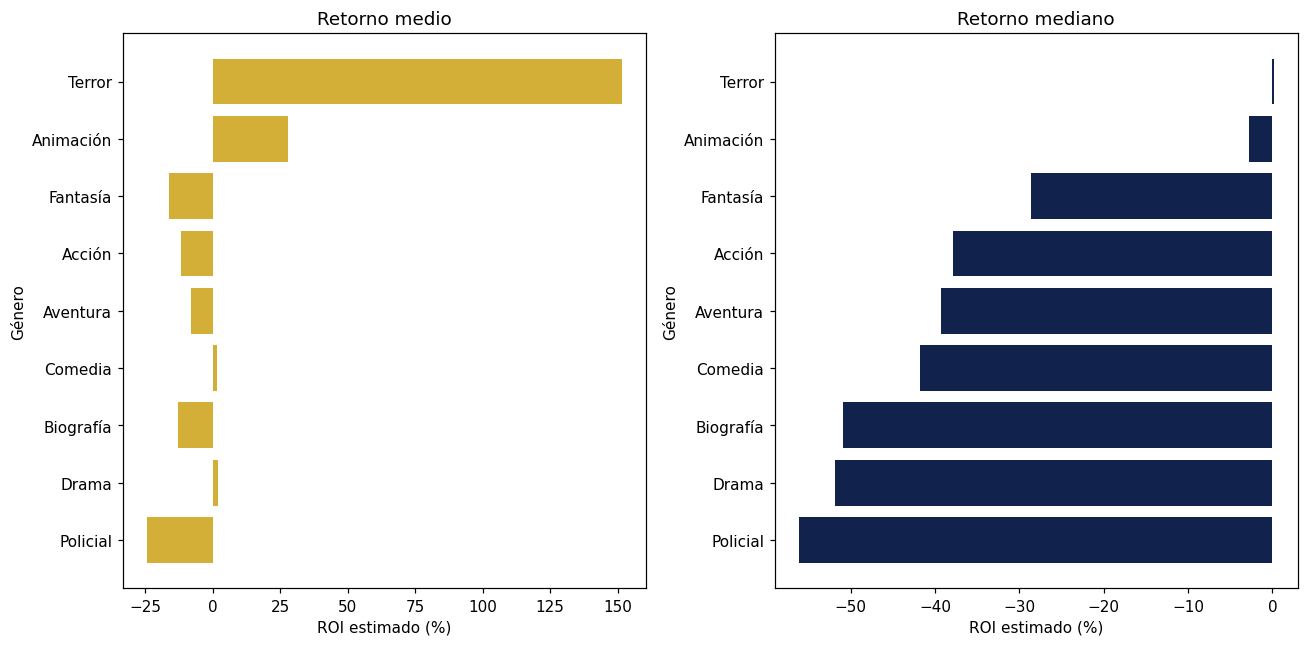

In [15]:
generos_comparacion = resumen_genero[
    resumen_genero['peliculas'] >= MIN_PELICULAS_COMPARABLES
].sort_values('roi_mediano_pct')

fig, ejes = plt.subplots(1, 2, figsize=(12, 6))
ejes[0].barh(generos_comparacion['genero'], generos_comparacion['roi_medio_pct'],
             color=DORADO_GRAFICO)
ejes[0].set_title('Retorno medio')
ejes[0].set_xlabel('ROI estimado (%)')
ejes[0].set_ylabel('Género')
ejes[1].barh(generos_comparacion['genero'], generos_comparacion['roi_mediano_pct'],
             color=AZUL_GRAFICO)
ejes[1].set_title('Retorno mediano')
ejes[1].set_xlabel('ROI estimado (%)')
ejes[1].set_ylabel('Género')
fig.tight_layout()
fig.savefig(carpeta_salidas / '38_grafico.png', dpi=150, bbox_inches='tight')
plt.show()


**Observaciones del gráfico:** en terror, el ROI medio es 151,6 % y el mediano apenas 0,2 %: unos pocos éxitos extremos elevan mucho el promedio. Las barras están ordenadas por mediana para comparar el resultado típico, y los grupos pequeños quedan fuera de esta visualización.

In [16]:
print('Películas con mayor ROI en el universo principal:')
display(universo_negocio.sort_values('roi_salas_estimado', ascending=False)
        [['titulo','genero','presupuesto_usd',
          'recaudacion_mundial_usd','roi_pct']].head(8).round(1))

# Contrastamos importes pequeños: un múltiplo enorme no prueba un error.
casos_a_revisar = datos.loc[datos.titulo.isin(
    ['Platoon','Paranormal Activity','The Devil Inside']),
    ['titulo','anio_estreno','presupuesto_usd',
     'recaudacion_mundial_usd','multiplo_boleteria','escala_dudosa']]
print('Casos que ayudan a distinguir errores de éxitos reales:')
display(casos_a_revisar.round(1))

Películas con mayor ROI en el universo principal:
Casos que ayudan a distinguir errores de éxitos reales:


,titulo,genero,presupuesto_usd,recaudacion_mundial_usd,roi_pct
7312,The Devil Inside,Terror,1000000.0,101758490.0,3291.9
990,Saw,Terror,1200000.0,103911669.0,2786.4
7397,E.T. the Extra-Terrestrial,Familiar,10500000.0,792910554.0,2417.2
5548,My Big Fat Greek Wedding,Comedia,5000000.0,368744044.0,2358.3
1302,The Full Monty,Comedia,3500000.0,257938649.0,2356.6
2217,Insidious,Terror,1500000.0,99557032.0,2112.4
4566,Unfriended,Terror,1000000.0,62882090.0,1996.1
217,Paranormal Activity 2,Terror,3000000.0,177512032.0,1872.4


,titulo,anio_estreno,presupuesto_usd,recaudacion_mundial_usd,multiplo_boleteria,escala_dudosa
263,Platoon,1986,6000.0,138545632.0,23090.9,True
5886,Paranormal Activity,2007,15000.0,193355800.0,12890.4,True
7312,The Devil Inside,2012,1000000.0,101758490.0,101.8,False


Observaciones: las medias pueden quedar muy por encima de las medianas porque unas pocas películas tienen retornos enormes. En terror, por ejemplo, The Devil Inside y Saw aparecen entre los máximos del universo principal. La base registra USD 1 millón de presupuesto para The Devil Inside y [The Numbers](https://www.the-numbers.com/movie/Devil-Inside-The) informa el mismo orden de magnitud: es un éxito extremo plausible, no una cifra que debamos cambiar solo por ser grande.

El filtro de escala de 1.6 también contiene casos distintos. La base registra USD 6000 para Platoon, mientras que una [crónica de la época](https://time.com/3834671/platoon-oliver-stone-charlie-sheen-movie-review/) informa USD 6 millones: hay evidencia de un error de escala. En cambio, [Paramount](https://ir.paramount.com/static-files/f55db0fb-b0ca-455f-a36a-bc1f5dc03368) confirma el presupuesto de USD 15.000 de Paranormal Activity: su múltiplo excepcional refleja un caso real de muy bajo presupuesto. No corregimos masivamente los demás casos sin verificar cada fuente. El universo principal excluye provisionalmente los presupuestos inferiores a USD 1 millón y la comparación de medias muestra cuánto cambia la lectura.

Películas con puntaje IMDb y ROI: 5192
Correlación IMDb–ROI: 0.173


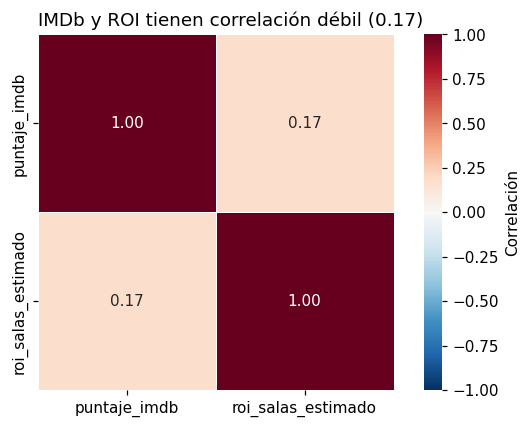

In [17]:
# Correlación de Pearson en el mismo universo usado para comparar retornos.
variables_correlacion = ['puntaje_imdb','roi_salas_estimado']
matriz_correlacion = universo_negocio[variables_correlacion].corr()
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(matriz_correlacion, annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            linewidths=0.5, square=True,
            cbar_kws={'label':'Correlación'}, ax=ax)
correlacion_imdb_roi = matriz_correlacion.loc[
    'puntaje_imdb','roi_salas_estimado']
ax.set_title(f'IMDb y ROI tienen correlación débil ({correlacion_imdb_roi:.2f})',
             loc='left')
fig.tight_layout()
fig.savefig(carpeta_salidas / '42_grafico.png', dpi=150, bbox_inches='tight')
plt.show()

print('Películas con puntaje IMDb y ROI:',
      universo_negocio[variables_correlacion].dropna().shape[0])
print('Correlación IMDb–ROI:', round(correlacion_imdb_roi, 3))

La correlación entre IMDb y ROI es positiva pero débil, aproximadamente 0,17. No permite asegurar que una buena puntuación implique rentabilidad. Además, el puntaje se conoce después del estreno: no lo podemos usar como criterio previo de inversión.

## 3.3 ¿Dónde está el riesgo?


In [18]:
FRACCION_PEOR_DECIL = 0.10

def retorno_peor_decil(serie):
    limite = serie.quantile(FRACCION_PEOR_DECIL)
    return serie.loc[serie <= limite].mean()

def tabla_riesgo(columna):
    tabla = universo_negocio.groupby(columna).agg(
        peliculas=('id_pelicula','size'),
        roi_mediano_pct=('roi_pct','median'),
        fracaso_pct=('fracaso_25','mean'),
        perdida_roi_pct=('perdida_roi','mean'),
        roi_peor_decil_pct=('roi_pct',retorno_peor_decil)).reset_index()
    tabla['fracaso_pct'] = 100 * tabla.fracaso_pct
    tabla['perdida_roi_pct'] *= 100
    return tabla.sort_values('peliculas', ascending=False)

riesgo_genero = tabla_riesgo('genero')
riesgo_secuela = tabla_riesgo('es_secuela')
print('Riesgo por género (ROI y fracaso en porcentaje):')
display(riesgo_genero.round(1))
print('Riesgo por franquicia (ROI y fracaso en porcentaje):')
display(riesgo_secuela.round(1))

# Aplicamos el mismo criterio de dominancia a las dos categorías de franquicia.
secuela_si = riesgo_secuela.loc[
    riesgo_secuela.es_secuela == 'Si'].iloc[0]
secuela_no = riesgo_secuela.loc[
    riesgo_secuela.es_secuela == 'No'].iloc[0]
print('Dominancia por franquicia:')
if (secuela_si.roi_mediano_pct > secuela_no.roi_mediano_pct
        and secuela_si.fracaso_pct < secuela_no.fracaso_pct):
    print('Las secuelas dominan a las no secuelas en mediana y fracaso.')
else:
    print('No hay dominancia de secuelas sobre no secuelas.')

# Dominancia compara mediana y fracaso; la propia fila no se domina a sí misma.
comparables = riesgo_genero.loc[
    riesgo_genero.peliculas >= MIN_PELICULAS_COMPARABLES].reset_index(drop=True).copy()
dominador_ejemplo = []
for i in range(len(comparables)):
    actual = comparables.iloc[i]
    mejor_retorno = comparables.roi_mediano_pct >= actual.roi_mediano_pct
    menor_fracaso = comparables.fracaso_pct <= actual.fracaso_pct
    ventaja_estricta = ((comparables.roi_mediano_pct > actual.roi_mediano_pct)
                        | (comparables.fracaso_pct < actual.fracaso_pct))
    nombres = comparables.loc[mejor_retorno & menor_fracaso & ventaja_estricta,
                             'genero']
    if len(nombres) > 0:
        dominador_ejemplo.append(nombres.iloc[0])
    else:
        dominador_ejemplo.append('Ninguno')

comparables['dominador_ejemplo'] = dominador_ejemplo
print('Dominancia entre géneros con al menos', MIN_PELICULAS_COMPARABLES,
      'películas:')
display(comparables.sort_values('roi_mediano_pct', ascending=False)
        [['genero','peliculas','roi_mediano_pct','fracaso_pct',
          'roi_peor_decil_pct','dominador_ejemplo']].round(1))
print('Géneros no dominados:',
      ', '.join(list(comparables.loc[
          comparables.dominador_ejemplo == 'Ninguno', 'genero'])))

Riesgo por género (ROI y fracaso en porcentaje):
Riesgo por franquicia (ROI y fracaso en porcentaje):
Dominancia por franquicia:
Las secuelas dominan a las no secuelas en mediana y fracaso.
Dominancia entre géneros con al menos 30 películas:
Géneros no dominados: Animación, Terror


,genero,peliculas,roi_mediano_pct,fracaso_pct,perdida_roi_pct,roi_peor_decil_pct
5,Comedia,1405,-41.7,62.8,70.3,-95.7
0,Acción,1377,-37.8,62.8,69.9,-93.2
6,Drama,829,-51.8,65.0,71.2,-98.0
10,Policial,384,-56.2,71.1,76.6,-97.3
2,Aventura,317,-39.3,61.5,69.4,-96.3
3,Biografía,306,-50.9,68.3,74.8,-95.6
1,Animación,272,-2.8,41.9,51.8,-89.1
13,Terror,236,0.2,42.8,50.0,-92.8
8,Fantasía,42,-28.6,57.1,66.7,-96.1
9,Misterio,17,-34.1,58.8,58.8,-99.3


,es_secuela,peliculas,roi_mediano_pct,fracaso_pct,perdida_roi_pct,roi_peor_decil_pct
0,No,4647,-44.6,64.5,71.3,-96.2
1,Si,562,-1.5,41.1,50.2,-86.6


,genero,peliculas,roi_mediano_pct,fracaso_pct,roi_peor_decil_pct,dominador_ejemplo
7,Terror,236,0.2,42.8,-92.8,Ninguno
6,Animación,272,-2.8,41.9,-89.1,Ninguno
8,Fantasía,42,-28.6,57.1,-96.1,Animación
1,Acción,1377,-37.8,62.8,-93.2,Animación
4,Aventura,317,-39.3,61.5,-96.3,Animación
0,Comedia,1405,-41.7,62.8,-95.7,Acción
5,Biografía,306,-50.9,68.3,-95.6,Comedia
2,Drama,829,-51.8,65.0,-98.0,Comedia
3,Policial,384,-56.2,71.1,-97.3,Comedia


Las tablas muestran el retorno típico, la frecuencia de fracaso según 2,5× y cuánto se pierde en el peor decil. Agregamos también la frecuencia de ROI negativo para distinguir ambas definiciones de pérdida.

La dominancia se calcula con mediana y frecuencia de fracaso comercial. Es una comparación histórica entre grupos; no prueba que hacer una secuela cause un mejor resultado.

## 4.1 Evolución nominal y real de la recaudación


In [19]:
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

pio.templates.default = 'plotly_white'
GRIS_GRAFICO = '#BBBBBB'

figura_evolucion = go.Figure()
figura_evolucion.add_trace(go.Scatter(
    x=serie_regular.anio_estreno, y=serie_regular.nominal_millones,
    mode='lines', name='Dólares corrientes',
    line={'color':AZUL_GRAFICO,'width':2}))
figura_evolucion.add_trace(go.Scatter(
    x=serie_regular.anio_estreno, y=serie_regular.real_millones,
    mode='lines', name='Dólares de 2020',
    line={'color':DORADO_GRAFICO,'width':2}))
figura_evolucion.update_layout(
    title='La recaudación mediana creció menos al ajustar por inflación',
    xaxis_title='Año de estreno',
    yaxis_title='Recaudación mediana por película (USD millones)',
    hovermode='x unified', height=460)
figura_evolucion.update_yaxes(rangemode='tozero')
figura_evolucion.write_html(carpeta_salidas / 'evolucion_interactiva.html', include_plotlyjs='cdn')
figura_evolucion.show()

print('Años mostrados:', len(serie_regular),
      '| desde', serie_regular.anio_estreno.min(),
      'hasta', serie_regular.anio_estreno.max())

Años mostrados: 35 | desde 1985 hasta 2019


**Observaciones:** la mediana de los años 2010 supera a la de los 1990 tanto en dólares corrientes como en dólares de 2020. El aumento parece de 3,2 veces sin ajustar y de 2,1 veces al corregir la inflación: parte del crecimiento nominal era un cambio en el valor del dólar.

## 4.2 Distribución del ROI estimado


Películas mostradas: 5209
Películas con ROI estimado negativo: 3596 (69.0%)
ROI mayores que 300 % agrupados visualmente: 174
ROI medio y mediano (%): 3.2 y -39.8


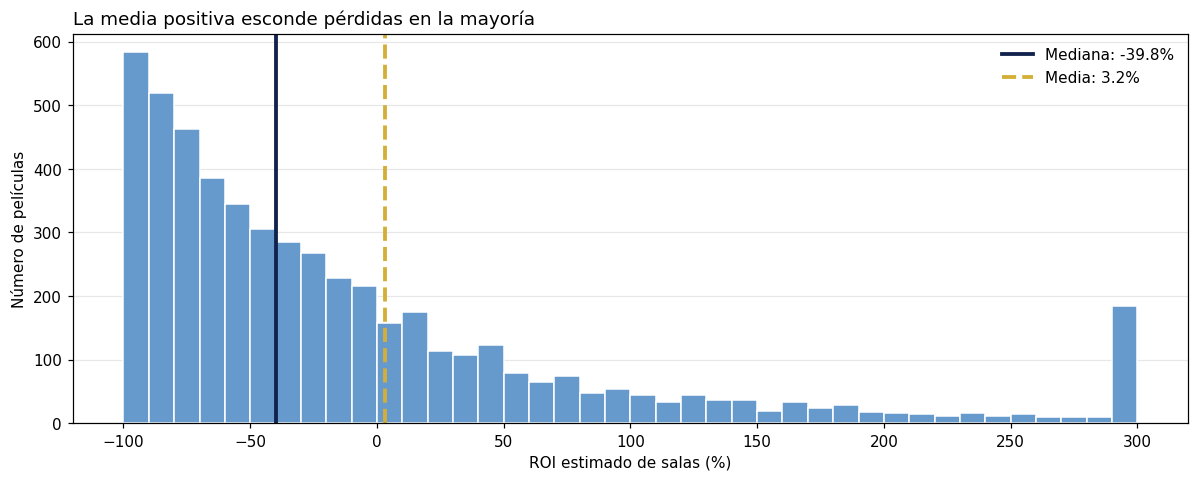

In [20]:
ROI_TOPE_VISUAL_PCT = 300
CANTIDAD_BINS_ROI = 40

roi_visual = universo_negocio[['roi_pct']].copy()
roi_visual['roi_grafico_pct'] = roi_visual.roi_pct.clip(
    upper=ROI_TOPE_VISUAL_PCT)
media_roi = roi_visual.roi_pct.mean()
mediana_roi = roi_visual.roi_pct.median()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.hist(roi_visual.roi_grafico_pct, bins=CANTIDAD_BINS_ROI,
        color=AZUL_CLARO_GRAFICO, edgecolor='white')
ax.axvline(mediana_roi, color=AZUL_GRAFICO, linewidth=2.5,
           label=f'Mediana: {mediana_roi:.1f}%')
ax.axvline(media_roi, color=DORADO_GRAFICO, linewidth=2.5,
           linestyle='--', label=f'Media: {media_roi:.1f}%')
ax.set_title('La media positiva esconde pérdidas en la mayoría', loc='left')
ax.set_xlabel('ROI estimado de salas (%)')
ax.set_ylabel('Número de películas')
ax.set_ylim(0, None)
ax.legend(frameon=False)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(carpeta_salidas / '52_grafico.png', dpi=150, bbox_inches='tight')
plt.show()

print('Películas mostradas:', len(roi_visual))
print('Películas con ROI estimado negativo:',
      (roi_visual.roi_pct < 0).sum(),
      f'({(roi_visual.roi_pct < 0).mean():.1%})')
print('ROI mayores que', ROI_TOPE_VISUAL_PCT, '% agrupados visualmente:',
      (roi_visual.roi_pct > ROI_TOPE_VISUAL_PCT).sum())
print('ROI medio y mediano (%):',
      round(media_roi, 1), 'y', round(mediana_roi, 1))

**Observaciones:** aunque el ROI medio es 3,2 %, el 69,0 % de las películas tiene ROI negativo y la mediana es −39,8 %: el promedio no describe a la película típica. Los 174 retornos superiores a 300 % elevan la media y se agrupan solo en la visualización, sin cambiar los datos.

## 4.3 Retorno mediano por género


In [21]:
generos_grafico = comparables.sort_values('roi_mediano_pct')

figura_generos = px.bar(
    generos_grafico, x='roi_mediano_pct', y='genero',
    orientation='h', text='roi_mediano_pct',
    hover_data=['peliculas','fracaso_pct','roi_peor_decil_pct'],
    color_discrete_sequence=[AZUL_GRAFICO],
    labels={'roi_mediano_pct':'ROI mediano estimado (%)',
            'genero':'Género',
            'peliculas':'Películas',
            'fracaso_pct':'Fracaso según 2,5× (%)',
            'roi_peor_decil_pct':'ROI medio del peor decil (%)'},
    title='Terror y animación encabezan el ROI mediano entre géneros comparables')
figura_generos.update_traces(texttemplate='%{text:.1f}%',
                             textposition='outside')
figura_generos.update_layout(height=530,
                             margin={'l':90,'r':80,'t':80,'b':60})
figura_generos.write_html(carpeta_salidas / 'generos_interactivo.html', include_plotlyjs='cdn')
figura_generos.show()

print('Géneros mostrados:', len(generos_grafico),
      '| mínimo por género:', MIN_PELICULAS_COMPARABLES)

Géneros mostrados: 9 | mínimo por género: 30


**Observaciones:** entre los nueve géneros comparables, solo terror tiene una mediana positiva y es apenas 0,2 %; animación le sigue con −2,8 % y policial queda último con −56,2 %. Incluso los grupos mejor ubicados pueden perder, por lo que el orden se debe leer junto con el tamaño y el riesgo que aparecen al pasar el cursor.

## 4.4 Presupuesto frente a recaudación


Películas mostradas: 5209 | excluidas por importe cero para la escala log: 0


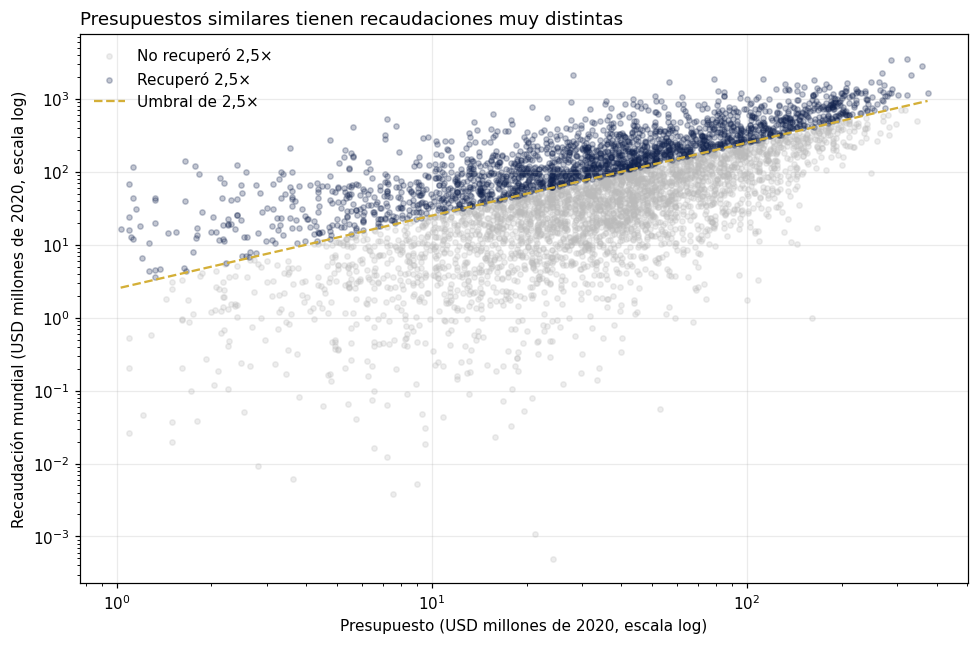

In [22]:
# La escala logarítmica requiere importes estrictamente positivos.
dispersion = universo_negocio.loc[
    (universo_negocio.presupuesto_2020_usd > 0)
    & (universo_negocio.recaudacion_2020_usd > 0)].copy()
dispersion['presupuesto_millones'] = (
    dispersion.presupuesto_2020_usd / USD_POR_MILLON)
dispersion['recaudacion_millones'] = (
    dispersion.recaudacion_2020_usd / USD_POR_MILLON)

fig, ax = plt.subplots(figsize=(9, 6))
for resultado, color, etiqueta in [
    ('No', GRIS_GRAFICO, 'No recuperó 2,5×'),
    ('Sí', AZUL_GRAFICO, 'Recuperó 2,5×')
]:
    grupo = dispersion.loc[dispersion.recupero_2_5x == resultado]
    ax.scatter(grupo.presupuesto_millones, grupo.recaudacion_millones,
               s=12, alpha=0.25, color=color, label=etiqueta)

presupuesto_min = dispersion.presupuesto_millones.min()
presupuesto_max = dispersion.presupuesto_millones.max()
ax.plot([presupuesto_min, presupuesto_max],
        [UMBRAL_RECUPERO * presupuesto_min,
         UMBRAL_RECUPERO * presupuesto_max],
        color=DORADO_GRAFICO, linestyle='--', label='Umbral de 2,5×')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title('Presupuestos similares tienen recaudaciones muy distintas',
             loc='left')
ax.set_xlabel('Presupuesto (USD millones de 2020, escala log)')
ax.set_ylabel('Recaudación mundial (USD millones de 2020, escala log)')
ax.legend(frameon=False)
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(carpeta_salidas / '58_grafico.png', dpi=150, bbox_inches='tight')
plt.show()

print('Películas mostradas:', len(dispersion),
      '| excluidas por importe cero para la escala log:',
      len(universo_negocio) - len(dispersion))

**Observaciones:** películas con presupuestos parecidos alcanzan recaudaciones muy diferentes, por lo que un presupuesto mayor no asegura recuperar la inversión. La línea de 2,5× separa los resultados comerciales y la transparencia deja ver dónde se concentran las películas superpuestas.

# Etapa 5: propuesta de inversión

## 5.1 Definir los grupos

In [23]:
CORTES_PRESUPUESTO_M = [0, 10, 30, 70, np.inf]
NOMBRES_TRAMOS = ['Hasta 10', '10-30', '30-70', 'Más de 70']

portafolio_base = universo_negocio.copy()
portafolio_base['presupuesto_millones'] = (
    portafolio_base.presupuesto_2020_usd / USD_POR_MILLON)
portafolio_base['tramo_presupuesto'] = pd.cut(
    portafolio_base.presupuesto_millones,
    bins=CORTES_PRESUPUESTO_M, labels=NOMBRES_TRAMOS)

# Verificamos que los tramos propuestos tengan casos suficientes.
resumen_tramos = portafolio_base.groupby(
    'tramo_presupuesto', observed=True).agg(
        peliculas=('id_pelicula','size'),
        presupuesto_mediano_m=('presupuesto_millones','median')).reset_index()
print('Películas y presupuesto mediano por tramo:')
display(resumen_tramos.round(1))

# Cada fila define un grupo observable; la asignación se decide en 5.2.
grupos_elegidos = pd.DataFrame([
    {'grupo':'Animación, más de 70 M, secuela',
     'genero':'Animación', 'tramo':'Más de 70', 'es_secuela':'Si'},
    {'grupo':'Acción, 30-70 M, secuela',
     'genero':'Acción', 'tramo':'30-70', 'es_secuela':'Si'},
    {'grupo':'Comedia, 30-70 M, secuela',
     'genero':'Comedia', 'tramo':'30-70', 'es_secuela':'Si'},
    {'grupo':'Terror, hasta 10 M, no secuela',
     'genero':'Terror', 'tramo':'Hasta 10', 'es_secuela':'No'}
])

filas_grupos = []
retornos_historicos = {}
for i in range(len(grupos_elegidos)):
    criterio = grupos_elegidos.iloc[i]
    historicas = portafolio_base.loc[
        (portafolio_base.genero == criterio['genero'])
        & (portafolio_base.tramo_presupuesto == criterio['tramo'])
        & (portafolio_base.es_secuela == criterio['es_secuela'])]
    retornos_historicos[criterio['grupo']] = (
        historicas.roi_salas_estimado.values)
    filas_grupos.append({
        'grupo':criterio['grupo'],
        'peliculas_historicas':len(historicas),
        'presupuesto_mediano_m':historicas.presupuesto_millones.median(),
        'roi_mediano_pct':100 * historicas.roi_salas_estimado.median(),
        'perdida_roi_pct':100 * (historicas.roi_salas_estimado < 0).mean(),
        'fracaso_pct':100 * historicas.fracaso_25.mean()
    })

resumen_grupos = pd.DataFrame(filas_grupos)
print('Cuatro grupos propuestos; presupuestos en USD millones de 2020:')
display(resumen_grupos.round(1))
print('Mínimo de películas históricas por grupo:',
      resumen_grupos.peliculas_historicas.min())

# Comparamos los grupos intermedios con películas no secuela equivalentes.
comparadores = portafolio_base.loc[
    portafolio_base.genero.isin(['Acción', 'Comedia'])
    & (portafolio_base.tramo_presupuesto == '30-70')]
comparacion_secuela = comparadores.groupby(
    ['genero', 'es_secuela']).agg(
        peliculas=('id_pelicula', 'size'),
        roi_mediano_pct=('roi_salas_estimado', 'median'),
        fracaso_pct=('fracaso_25', 'mean')).reset_index()
comparacion_secuela['roi_mediano_pct'] = (
    100 * comparacion_secuela.roi_mediano_pct)
comparacion_secuela['fracaso_pct'] = (
    100 * comparacion_secuela.fracaso_pct)
print('Acción y comedia de 30–70 M: secuelas frente a no secuelas:')
display(comparacion_secuela.round(1))

Películas y presupuesto mediano por tramo:
Cuatro grupos propuestos; presupuestos en USD millones de 2020:
Mínimo de películas históricas por grupo: 33
Acción y comedia de 30–70 M: secuelas frente a no secuelas:


,tramo_presupuesto,peliculas,presupuesto_mediano_m
0,Hasta 10,683,5.7
1,10-30,1610,19.3
2,30-70,1724,43.6
3,Más de 70,1192,109.2


,grupo,peliculas_historicas,presupuesto_mediano_m,roi_mediano_pct,perdida_roi_pct,fracaso_pct
0,"Animación, más de 70 M, secuela",42,112.9,41.0,31.0,26.2
1,"Acción, 30-70 M, secuela",80,47.9,-8.6,53.8,46.2
2,"Comedia, 30-70 M, secuela",33,43.8,-4.0,51.5,36.4
3,"Terror, hasta 10 M, no secuela",66,5.2,44.6,40.9,37.9


,genero,es_secuela,peliculas,roi_mediano_pct,fracaso_pct
0,Acción,No,399,-51.7,71.9
1,Acción,Si,80,-8.6,46.2
2,Comedia,No,466,-47.8,65.9
3,Comedia,Si,33,-4.0,36.4


Elegimos cuatro grupos con criterios que se pueden comprobar: género, tramo de presupuesto y si es secuela. Los cortes de 10, 30 y 70 millones son una decisión de planificación, no límites dados por la consigna. Todos tienen al menos 30 antecedentes.

Animación secuela grande y terror barato tienen medianas positivas. Acción y comedia secuela de presupuesto medio tienen medianas ligeramente negativas, pero mejores que las no secuelas equivalentes. Les damos una participación acotada; no afirmamos que sean las mejores inversiones posibles.

## 5.2 Distribuir los USD 500 millones

In [24]:
CAPITAL_TOTAL_M = 500
FACTOR_COSTO_TOTAL = 1 + MARKETING_SOBRE_PRESUPUESTO

asignacion = pd.DataFrame([
    {'grupo':'Animación, más de 70 M, secuela', 'asignacion_m':170, 'proyectos':1},
    {'grupo':'Acción, 30-70 M, secuela', 'asignacion_m':144, 'proyectos':2},
    {'grupo':'Comedia, 30-70 M, secuela', 'asignacion_m':66, 'proyectos':1},
    {'grupo':'Terror, hasta 10 M, no secuela', 'asignacion_m':120, 'proyectos':15}
])
propuesta = resumen_grupos.merge(asignacion, on='grupo')
propuesta['capital_por_proyecto_m'] = propuesta.asignacion_m / propuesta.proyectos
propuesta['produccion_por_proyecto_m'] = propuesta.capital_por_proyecto_m / FACTOR_COSTO_TOTAL
propuesta['marketing_por_proyecto_m'] = (
    propuesta.produccion_por_proyecto_m * MARKETING_SOBRE_PRESUPUESTO)
propuesta['diferencia_vs_mediana_pct'] = (
    propuesta.produccion_por_proyecto_m / propuesta.presupuesto_mediano_m - 1) * 100
propuesta['participacion_pct'] = propuesta.asignacion_m / CAPITAL_TOTAL_M * 100
print('¿La asignación suma 500 millones?', propuesta['asignacion_m'].sum() == CAPITAL_TOTAL_M)
control_costos = (propuesta['produccion_por_proyecto_m']
                  + propuesta['marketing_por_proyecto_m']
                  - propuesta['capital_por_proyecto_m']).round(6)
print('Diferencia entre los costos y el capital por proyecto:')
display(control_costos)
display(propuesta.round(2))
print('Total asignado:', propuesta.asignacion_m.sum(), 'millones de USD')
print('Proyectos:', propuesta.proyectos.sum())


¿La asignación suma 500 millones? True
Diferencia entre los costos y el capital por proyecto:
Total asignado: 500 millones de USD
Proyectos: 19


0    0.0
1    0.0
2    0.0
3    0.0
dtype: float64

,grupo,peliculas_historicas,presupuesto_mediano_m,roi_mediano_pct,perdida_roi_pct,fracaso_pct,asignacion_m,proyectos,capital_por_proyecto_m,produccion_por_proyecto_m,marketing_por_proyecto_m,diferencia_vs_mediana_pct,participacion_pct
0,"Animación, más de 70 M, secuela",42,112.92,40.99,30.95,26.19,170,1,170.0,113.33,56.67,0.37,34.0
1,"Acción, 30-70 M, secuela",80,47.88,-8.56,53.75,46.25,144,2,72.0,48.00,24.00,0.25,28.8
2,"Comedia, 30-70 M, secuela",33,43.75,-4.02,51.52,36.36,66,1,66.0,44.00,22.00,0.56,13.2
3,"Terror, hasta 10 M, no secuela",66,5.17,44.58,40.91,37.88,120,15,8.0,5.33,2.67,3.16,24.0


Los USD 500 millones cubren producción **y** marketing. Por eso dividimos el capital por película entre 1,5 antes de compararlo con el presupuesto histórico de producción. Suponemos que el fondo financia todo el proyecto y recibe el ingreso del estudio estimado en el modelo; en la realidad habría que acordarlo por contrato.

La propuesta tiene 19 proyectos. La animación concentra el 34 % del capital en una película y conseguir 15 títulos de terror comparables en tres años requiere verificar la oferta. La cantidad de proyectos no elimina estos riesgos.

Los montos se expresan en USD de 2020 para compararlos con la base. Es una planificación a poder de compra constante: al invertir en otro año hay que actualizar el capital y los costos con el IPC correspondiente. No tenemos esos índices futuros en los datos.

## 5.3 Retorno y riesgo del portafolio

In [25]:
N_SIMULACIONES = 10_000
SEMILLA_SIMULACION = 2026
retorno_central_pct = (
    (propuesta.asignacion_m * propuesta.roi_mediano_pct).sum() / CAPITAL_TOTAL_M)
print('Escenario central ponderando medianas:', f'{retorno_central_pct:.1f}%')
print('Resultado central en millones:', round(CAPITAL_TOTAL_M * retorno_central_pct / 100, 1))

generador = np.random.default_rng(SEMILLA_SIMULACION)
generador_compartido = np.random.default_rng(SEMILLA_SIMULACION + 1)
resultado_independiente_m = [0.0] * N_SIMULACIONES
resultado_compartido_m = [0.0] * N_SIMULACIONES

for i in range(len(propuesta)):
    fila = propuesta.iloc[i]
    roi_grupo = retornos_historicos[fila['grupo']]
    cantidad = int(fila['proyectos'])
    for simulacion in range(N_SIMULACIONES):
        # Sorteamos los retornos de las películas de este grupo.
        sorteos = generador.choice(roi_grupo, size=cantidad, replace=True)
        ganancia = fila['capital_por_proyecto_m'] * sorteos.sum()
        resultado_independiente_m[simulacion] += ganancia

    for simulacion in range(N_SIMULACIONES):
        # Acá todas las películas del grupo comparten el mismo resultado.
        sorteo_grupo = generador_compartido.choice(roi_grupo)
        resultado_compartido_m[simulacion] += fila['asignacion_m'] * sorteo_grupo

retornos_independientes = pd.Series(resultado_independiente_m) / CAPITAL_TOTAL_M
retornos_compartidos = pd.Series(resultado_compartido_m) / CAPITAL_TOTAL_M
filas_escenarios = []
for nombre, retornos in [('Proyectos sorteados por separado', retornos_independientes),
                         ('Resultado compartido dentro de cada grupo', retornos_compartidos)]:
    filas_escenarios.append({
        'supuesto': nombre,
        'prob_perder_capital_pct': 100 * (retornos < 0).mean(),
        'roi_decil_inferior_pct': 100 * retornos.quantile(0.10),
        'roi_mediano_pct': 100 * retornos.median()
    })
escenarios = pd.DataFrame(filas_escenarios)
display(escenarios.round(2))


Escenario central ponderando medianas: 21.6%
Resultado central en millones: 108.2


,supuesto,prob_perder_capital_pct,roi_decil_inferior_pct,roi_mediano_pct
0,Proyectos sorteados por separado,0.88,45.74,113.15
1,Resultado compartido dentro de cada grupo,23.01,-25.81,59.28


Primero ponderamos las medianas de los grupos según el dinero asignado. Es un escenario central, no una ganancia garantizada.

Para la simulación usamos ciclos, listas y sorteos con NumPy. En cada repetición sumamos la ganancia o pérdida de los proyectos y la dividimos entre los USD 500 millones. Repetimos esto 10.000 veces y contamos cuántas terminan con retorno negativo.

Probamos también que todas las películas de un grupo compartan un resultado. Así vemos cuánto cambia el riesgo si se mueven juntas. El percentil 10 es el resultado por debajo del cual cae aproximadamente una de cada diez simulaciones; no es la pérdida máxima.


## 5.4 Sensibilidad a costos y éxitos extremos

In [26]:
# Reutilizamos los mismos sorteos para comparar los supuestos.
rng_sensibilidad = np.random.default_rng(2026)
resultados_sensibilidad = {}
for nombre, limite_roi, marketing in [
    ('Base: marketing 50 %', None, 0.5),
    ('ROI limitado a 1.000 %', 10, 0.5),
    ('Marketing 100 %, mismos proyectos', None, 1.0)
]:
    rng_sensibilidad = np.random.default_rng(2026)
    ingresos_m = [0.0] * N_SIMULACIONES
    costo_m = CAPITAL_TOTAL_M * (1 + marketing) / FACTOR_COSTO_TOTAL
    for i in range(len(propuesta)):
        fila = propuesta.iloc[i]
        cantidad = int(fila['proyectos'])
        for simulacion in range(N_SIMULACIONES):
            sorteos = rng_sensibilidad.choice(retornos_historicos[fila['grupo']],
                                              size=cantidad, replace=True)
            retornos = pd.Series(sorteos)
            if limite_roi is not None:
                retornos = retornos.clip(upper=limite_roi)
            ingreso = fila['capital_por_proyecto_m'] * (1 + retornos).sum()
            ingresos_m[simulacion] += ingreso
    roi_escenario = pd.Series(ingresos_m) / costo_m - 1
    resultados_sensibilidad[nombre] = {
        'capital_necesario_m': costo_m,
        'roi_mediano_pct': 100 * roi_escenario.median(),
        'prob_perder_pct': 100 * (roi_escenario < 0).mean()
    }
display(pd.DataFrame(resultados_sensibilidad).T.round(2))


,capital_necesario_m,roi_mediano_pct,prob_perder_pct
Base: marketing 50 %,500.00,113.15,0.88
ROI limitado a 1.000 %,500.00,85.45,1.32
"Marketing 100 %, mismos proyectos",666.67,59.86,6.07


Limitar el ROI de una película a 1.000 % sirve para ver cuánto dependemos de los éxitos extraordinarios. No cambiamos los datos históricos con ese límite.

Si marketing sube del 50 % al 100 % de producción, los mismos proyectos requieren unos USD 666,7 millones: superan la línea del fondo. Ese escenario compara la economía de los mismos proyectos; para seguir dentro de USD 500 millones habría que reducir o cofinanciar la cartera.

## 5.5 Dónde no invertir y limitaciones

In [27]:
no_invertir = []
for genero in ['Drama', 'Policial']:
    grupo = portafolio_base.loc[
        (portafolio_base.genero == genero)
        & (portafolio_base.tramo_presupuesto == '30-70')
        & (portafolio_base.es_secuela == 'No')]
    no_invertir.append({
        'grupo':genero + ', 30-70 M, no secuela',
        'peliculas_historicas':len(grupo),
        'roi_mediano_pct':100 * grupo.roi_salas_estimado.median(),
        'fracaso_pct':100 * grupo.fracaso_25.mean()
    })

print('Grupos que evitaríamos inicialmente:')
display(pd.DataFrame(no_invertir).round(1))

# Movemos los cortes para ver cuánto depende de ellos la tesis.
filas_sensibilidad_cortes = []
for corte_bajo, corte_medio, corte_alto in [(8,25,65), (10,30,70),
                                             (12,35,75)]:
    terror_bajo = portafolio_base.loc[
        (portafolio_base.genero == 'Terror')
        & (portafolio_base.es_secuela == 'No')
        & (portafolio_base.presupuesto_millones <= corte_bajo)]
    accion_media = portafolio_base.loc[
        (portafolio_base.genero == 'Acción')
        & (portafolio_base.es_secuela == 'Si')
        & (portafolio_base.presupuesto_millones > corte_medio)
        & (portafolio_base.presupuesto_millones <= corte_alto)]
    filas_sensibilidad_cortes.append({
        'cortes_millones':f'{corte_bajo}/{corte_medio}/{corte_alto}',
        'terror_n':len(terror_bajo),
        'terror_roi_mediano_pct':100 * terror_bajo.roi_salas_estimado.median(),
        'accion_n':len(accion_media),
        'accion_roi_mediano_pct':100 * accion_media.roi_salas_estimado.median()
    })

print('Sensibilidad de dos grupos a los cortes de presupuesto:')
display(pd.DataFrame(filas_sensibilidad_cortes).round(1))

Grupos que evitaríamos inicialmente:
Sensibilidad de dos grupos a los cortes de presupuesto:


,grupo,peliculas_historicas,roi_mediano_pct,fracaso_pct
0,"Drama, 30-70 M, no secuela",253,-61.6,68.4
1,"Policial, 30-70 M, no secuela",121,-60.0,75.2


,cortes_millones,terror_n,terror_roi_mediano_pct,accion_n,accion_roi_mediano_pct
0,8/25/65,56,80.6,73,2.4
1,10/30/70,66,44.6,80,-8.6
2,12/35/75,80,27.8,78,-11.1


No priorizaríamos dramas y policiales no secuelas de USD 30–70 millones: sus medianas son negativas y muestran una frecuencia elevada de fracaso. Esto no quiere decir que ninguna película de esos grupos pueda funcionar.

También dejaríamos los presupuestos menores a USD 1 millón sujetos a verificación, porque la base mezcla errores de escala con películas realmente baratas.

Limitaciones principales:
- Los presupuestos faltantes varían por década, género y país. La muestra financiera no representa por igual a todos los grupos.
- Elegimos los grupos mirando el desempeño histórico. Podrían no repetir esos resultados en proyectos nuevos.
- No conocemos contratos, streaming, costos reales ni correlaciones entre estrenos.
- La tesis depende de los cortes de presupuesto y de conseguir proyectos comparables.

La propuesta sirve para seleccionar proyectos a evaluar. Antes de comprometer capital hay que verificar cada presupuesto, la disponibilidad de títulos y las condiciones de participación.

In [28]:
print('Propuesta final:')
display(propuesta.round(2))
print('Resultados de la simulación:')
display(escenarios.round(2))


Propuesta final:
Resultados de la simulación:


,grupo,peliculas_historicas,presupuesto_mediano_m,roi_mediano_pct,perdida_roi_pct,fracaso_pct,asignacion_m,proyectos,capital_por_proyecto_m,produccion_por_proyecto_m,marketing_por_proyecto_m,diferencia_vs_mediana_pct,participacion_pct
0,"Animación, más de 70 M, secuela",42,112.92,40.99,30.95,26.19,170,1,170.0,113.33,56.67,0.37,34.0
1,"Acción, 30-70 M, secuela",80,47.88,-8.56,53.75,46.25,144,2,72.0,48.00,24.00,0.25,28.8
2,"Comedia, 30-70 M, secuela",33,43.75,-4.02,51.52,36.36,66,1,66.0,44.00,22.00,0.56,13.2
3,"Terror, hasta 10 M, no secuela",66,5.17,44.58,40.91,37.88,120,15,8.0,5.33,2.67,3.16,24.0


,supuesto,prob_perder_capital_pct,roi_decil_inferior_pct,roi_mediano_pct
0,Proyectos sorteados por separado,0.88,45.74,113.15
1,Resultado compartido dentro de cada grupo,23.01,-25.81,59.28


Estas son las tablas que vamos a usar para la presentación. Los gráficos quedan guardados en salidas y los números se pueden consultar en las celdas anteriores.
